# Investigating strategy rating results exploratorily

In [1]:
# import packages
import pandas as pd
import matplotlib.cm as cm
import matplotlib.pyplot as plt

## Read data, bring to wide format and combine with original dataset

Note: pandas' default `na_values` includes the string `"None"`, so a plain `pd.read_csv` silently
turns the model's `None` ratings into NaN. We pass `keep_default_na=False` to keep them as a real
category.

In [2]:
# reading data
ratings = pd.read_csv("data/ratings.csv", keep_default_na=False, na_values=[""])
orig_data = pd.read_csv("../orig_data/data_analysis_AI_dialogue_study.csv")

In [3]:
# bring to wide format
ratings_wide = ratings.pivot(index="conv_id", columns="strategy", values="rating")
ratings_wide = ratings_wide.reset_index()

In [4]:
# save columns for subsetting later
condition_cols = ratings_wide.columns.drop("conv_id")

In [5]:
# merge ratings into orig data
df_merged = orig_data.merge(
    ratings_wide,
    left_on="X",
    right_on="conv_id",
    how="left"
)
df_merged = df_merged.drop(columns="conv_id")

In [6]:
# save combined df
df_merged.to_csv("data/data_analysis_AI_dialogue_study_with_strategy_ratings.csv", index=False)

## Distribution of ratings per strategy 

In [7]:

print("rows:", len(ratings), "  conversations:", ratings["conv_id"].nunique(), "  strategies:", ratings["strategy"].nunique())
print(ratings["rating"].value_counts())

rows: 71994   conversations: 6558   strategies: 11
rating
Moderate    30223
Low         22669
High        15709
None         3393
Name: count, dtype: int64


/var/folders/g6/6tx7kz_51_92m63qx0q2c2lw0000gn/T/ipykernel_90813/260957468.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  viridis  = cm.get_cmap("viridis")


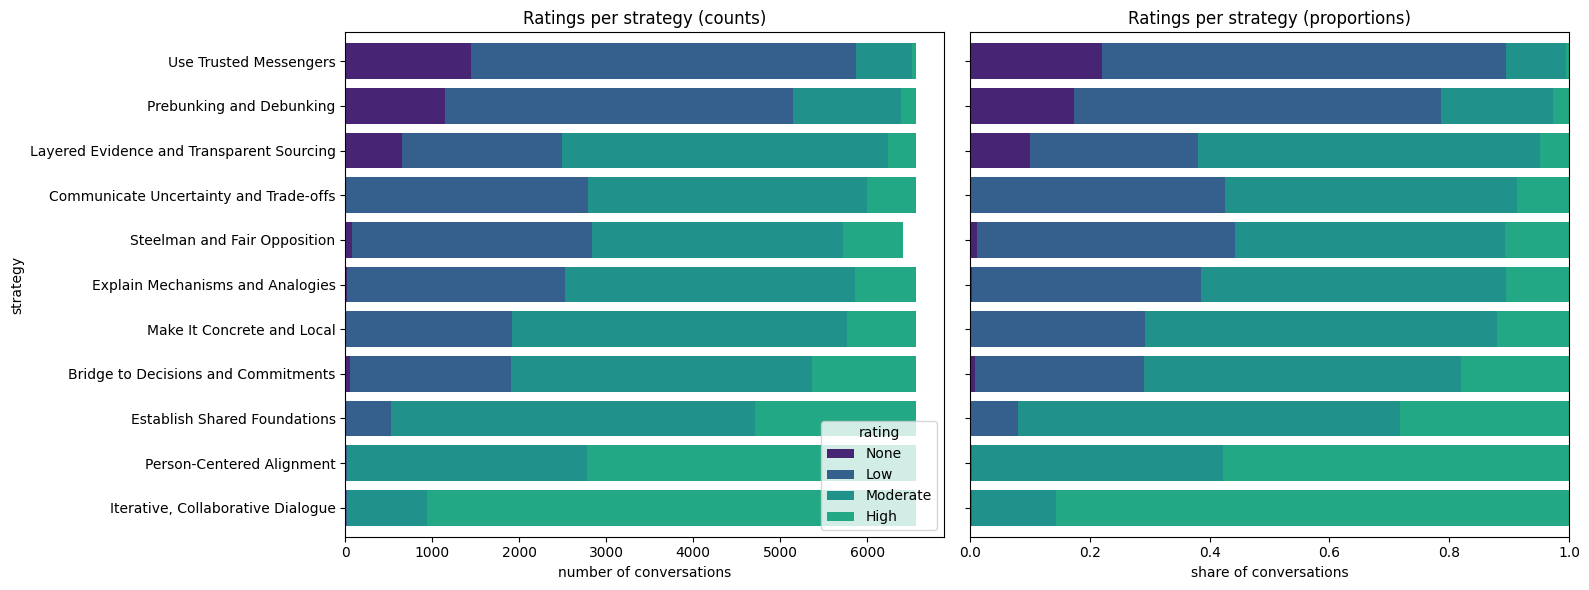

In [8]:
rating_order = ["None", "Low", "Moderate", "High"]
viridis  = cm.get_cmap("viridis")

colors = {"None": viridis(0.1), "Low":viridis(0.3), "Moderate":viridis(0.5), "High":viridis(0.6)}

counts = (
    ratings.groupby(["strategy", "rating"]).size()
     .unstack(fill_value=0)
     .reindex(columns=rating_order, fill_value=0)
)
# order strategies by how often they're rated High (most "intense" first)
counts = counts.loc[counts["High"].sort_values(ascending=False).index]
shares = counts.div(counts.sum(axis=1), axis=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

counts.plot(kind="barh", stacked=True, ax=ax1,
            color=[colors[r] for r in rating_order], width=0.8)
ax1.invert_yaxis()
ax1.set_xlabel("number of conversations")
ax1.set_title("Ratings per strategy (counts)")
ax1.legend(title="rating", loc="lower right")

shares.plot(kind="barh", stacked=True, ax=ax2,
            color=[colors[r] for r in rating_order], width=0.8, legend=False)
ax2.set_xlabel("share of conversations")
ax2.set_xlim(0, 1)
ax2.set_title("Ratings per strategy (proportions)")

plt.tight_layout()
plt.show()

Same overall view, but with the control condition excluded so the experimental conditions aren't pulled down by control conversations.

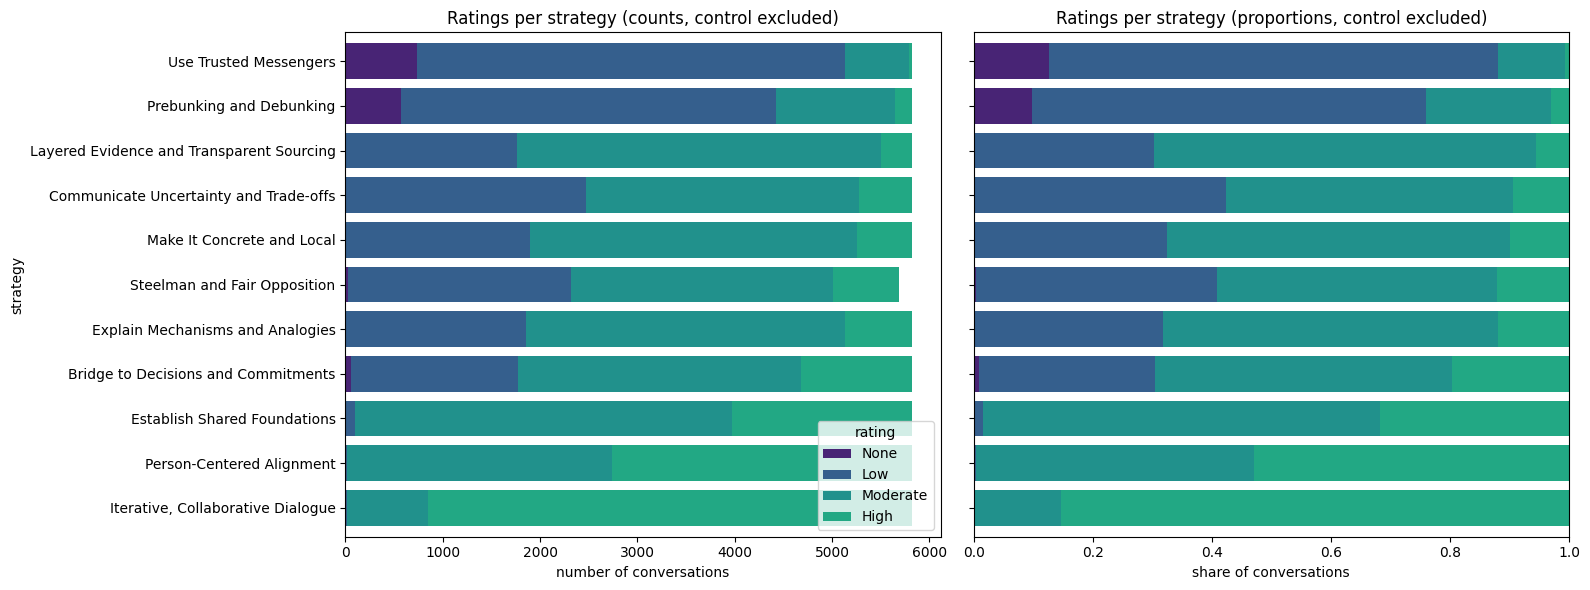

In [9]:
# exclude control conversations
non_control_ids = df_merged.loc[df_merged["condition"] != "control", "X"]
ratings_no_control = ratings[ratings["conv_id"].isin(non_control_ids)]

counts = (
    ratings_no_control.groupby(["strategy", "rating"]).size()
     .unstack(fill_value=0)
     .reindex(columns=rating_order, fill_value=0)
)
counts = counts.loc[counts["High"].sort_values(ascending=False).index]
shares = counts.div(counts.sum(axis=1), axis=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

counts.plot(kind="barh", stacked=True, ax=ax1,
            color=[colors[r] for r in rating_order], width=0.8)
ax1.invert_yaxis()
ax1.set_xlabel("number of conversations")
ax1.set_title("Ratings per strategy (counts, control excluded)")
ax1.legend(title="rating", loc="lower right")

shares.plot(kind="barh", stacked=True, ax=ax2,
            color=[colors[r] for r in rating_order], width=0.8, legend=False)
ax2.set_xlabel("share of conversations")
ax2.set_xlim(0, 1)
ax2.set_title("Ratings per strategy (proportions, control excluded)")

plt.tight_layout()
plt.show()

## Looking at strategies for different subsets of conversations

In [10]:
# dictionary to bring condition and interesting diff column together
# note: 'control' maps to None, so it is excluded from the big-effects subset below
condition_effect_dict = {
'vacc_bel+pol': ['diff_vacc_bel', 'diff_vacc_pol'],
'vacc_bel': ['diff_vacc_bel'],
'vacc_pol': ['diff_vacc_pol'],
'inequal_pol': ['diff_ineq_pol'],
'climate_bel': ['diff_clim_bel'],
'inequal_bel+pol': ['diff_ineq_pol', 'diff_ineq_bel'],
'climate_bel+pol': ['diff_clim_bel', 'diff_clim_pol'],
'climate_pol': ['diff_clim_pol'],
'control': None,
'inequal_bel': ['diff_ineq_bel']
}

# subset df with big effects (control is excluded because its entry is None)
def has_big_effect(row, condition_effect_dict, threshold=8):
    condition = row['condition']
    cols = condition_effect_dict.get(condition)
    if cols is None:
        return False
    return any(row[col] >= threshold for col in cols)

mask = df_merged.apply(has_big_effect, axis=1, condition_effect_dict=condition_effect_dict)
subset_df_big_effects = df_merged[mask].copy()

In [11]:
# bring to long format to have all ratings per person
df_long_subset = subset_df_big_effects.melt(
    id_vars="X",
    value_vars=condition_cols,
    var_name="strategy",
    value_name="rating"
)

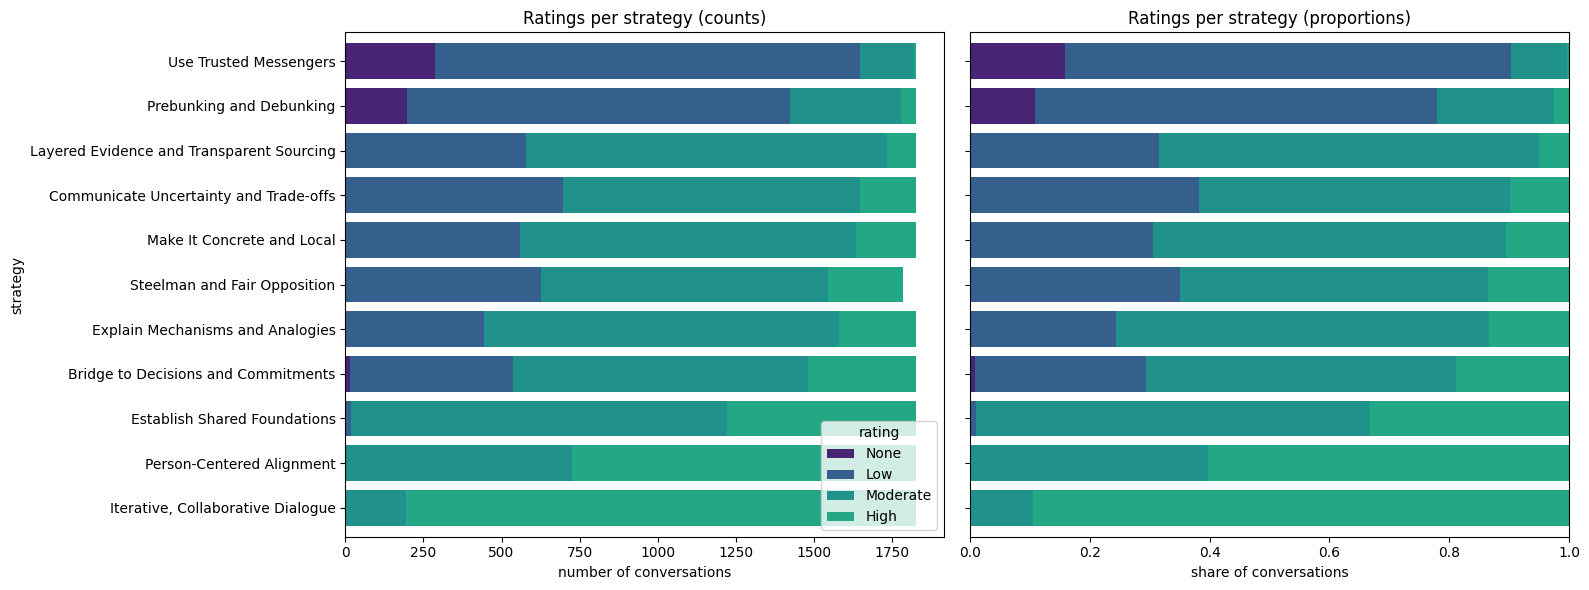

In [12]:

counts = (
    df_long_subset.groupby(["strategy", "rating"]).size()
     .unstack(fill_value=0)
     .reindex(columns=rating_order, fill_value=0)
)
# order strategies by how often they're rated High (most "intense" first)
counts = counts.loc[counts["High"].sort_values(ascending=False).index]
shares = counts.div(counts.sum(axis=1), axis=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

counts.plot(kind="barh", stacked=True, ax=ax1,
            color=[colors[r] for r in rating_order], width=0.8)
ax1.invert_yaxis()
ax1.set_xlabel("number of conversations")
ax1.set_title("Ratings per strategy (counts)")
ax1.legend(title="rating", loc="lower right")

shares.plot(kind="barh", stacked=True, ax=ax2,
            color=[colors[r] for r in rating_order], width=0.8, legend=False)
ax2.set_xlabel("share of conversations")
ax2.set_xlim(0, 1)
ax2.set_title("Ratings per strategy (proportions)")

plt.tight_layout()
plt.show()

### Per experimental condition

Same big-effects subset, broken down by condition. Strategies are kept in a fixed order across panels (overall ranking by share of "High" ratings) so the panels are visually comparable.

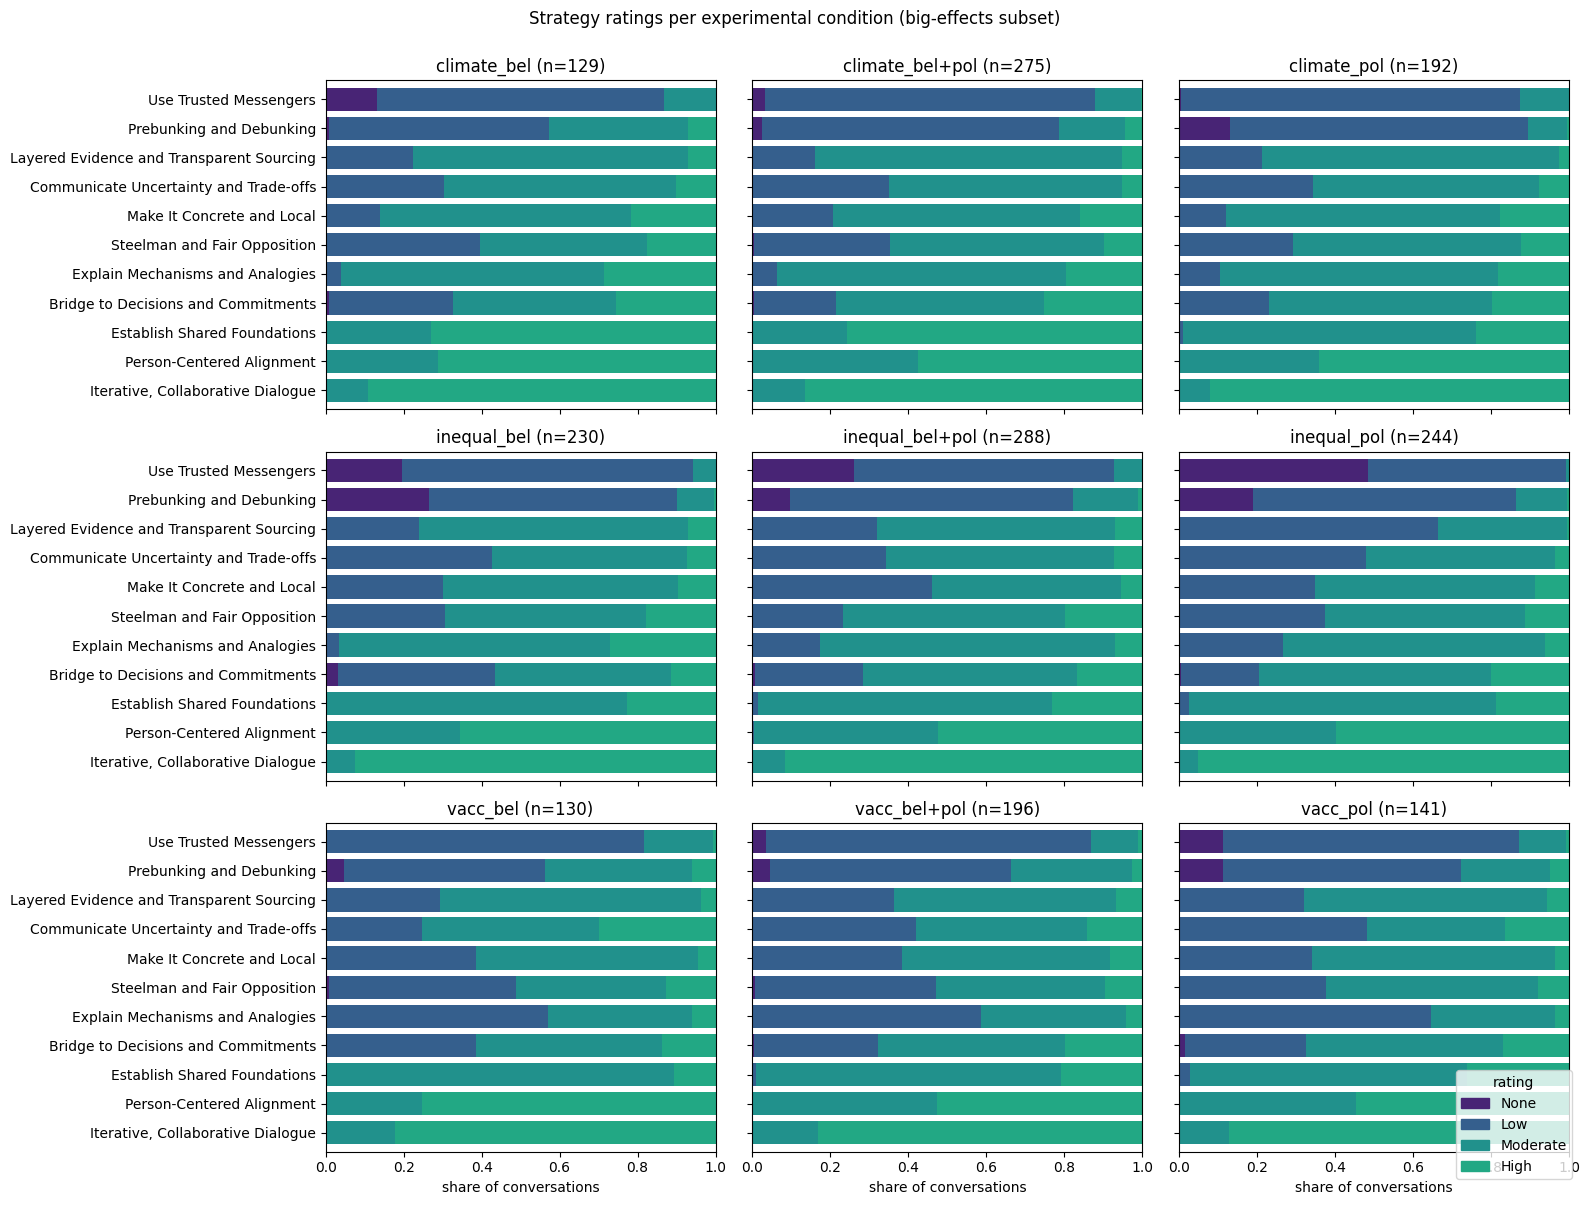

In [13]:
# fixed strategy order, based on overall "High" share in the big-effects subset
overall_counts = (
    df_long_subset.groupby(["strategy", "rating"]).size()
     .unstack(fill_value=0)
     .reindex(columns=rating_order, fill_value=0)
)
strategy_order = overall_counts["High"].sort_values(ascending=True).index.tolist()

conditions = sorted(c for c in subset_df_big_effects["condition"].unique() if c != "control")

ncols = 3
nrows = (len(conditions) + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows), sharex=True, sharey=True)
axes = axes.flatten()

for i, cond in enumerate(conditions):
    cond_df = subset_df_big_effects[subset_df_big_effects["condition"] == cond]
    cond_long = cond_df.melt(
        id_vars="X",
        value_vars=condition_cols,
        var_name="strategy",
        value_name="rating",
    )
    cond_counts = (
        cond_long.groupby(["strategy", "rating"]).size()
         .unstack(fill_value=0)
         .reindex(index=strategy_order, columns=rating_order, fill_value=0)
    )
    cond_shares = cond_counts.div(cond_counts.sum(axis=1), axis=0)

    ax = axes[i]
    cond_shares.plot(kind="barh", stacked=True, ax=ax,
                     color=[colors[r] for r in rating_order], width=0.8, legend=False)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_title(f"{cond} (n={cond_df['X'].nunique()})")
    ax.set_xlabel("share of conversations")
    ax.set_ylabel("")

for j in range(len(conditions), len(axes)):
    axes[j].set_visible(False)

handles = [plt.Rectangle((0, 0), 1, 1, color=colors[r]) for r in rating_order]
fig.legend(handles, rating_order, title="rating",
           loc="lower right", bbox_to_anchor=(0.99, 0.02))

fig.suptitle("Strategy ratings per experimental condition (big-effects subset)", y=1.0)
plt.tight_layout()
plt.show()

### Heatmap view

The grid above is hard to read across panels. We collapse the four rating levels to an intensity score (None=0, Low=1, Moderate=2, High=3) and average per strategy × condition, then show:

1. **Absolute mean intensity** — how strongly each strategy is used in each condition.
2. **Deviation from the strategy's overall mean** — directly highlights condition × strategy combinations that stand out (red = used more than average for that strategy, blue = used less).

Both are computed on the same big-effects subset (control already excluded).

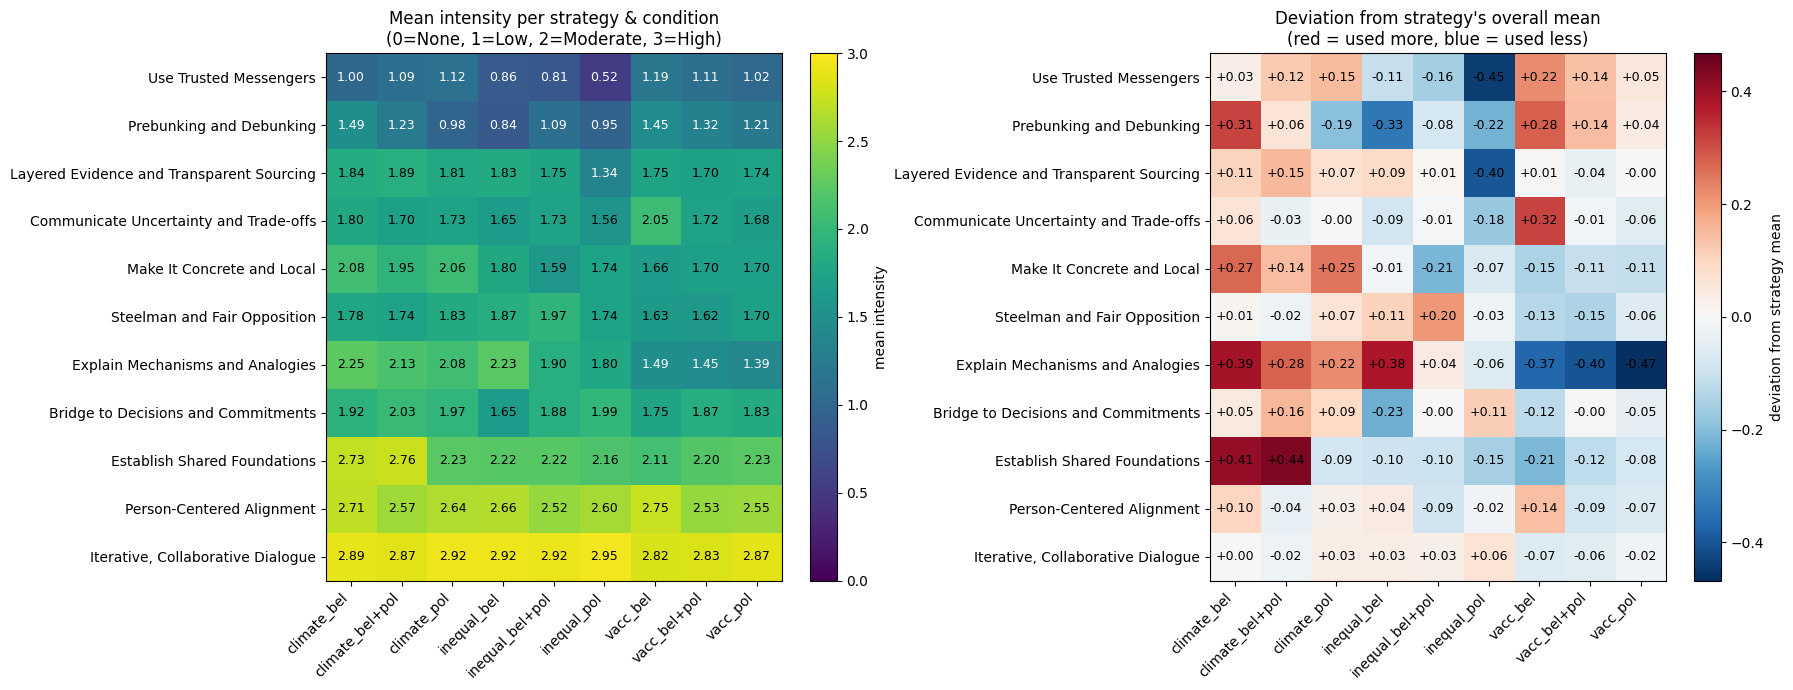

In [14]:
intensity_map = {"None": 0, "Low": 1, "Moderate": 2, "High": 3}

# long format including condition, with numeric intensity score
df_long_with_cond = subset_df_big_effects.melt(
    id_vars=["X", "condition"],
    value_vars=condition_cols,
    var_name="strategy",
    value_name="rating",
)
df_long_with_cond["intensity"] = df_long_with_cond["rating"].map(intensity_map)

# strategies (rows) in the same order as before; conditions (cols) sorted alphabetically
mean_intensity = (
    df_long_with_cond
    .groupby(["strategy", "condition"])["intensity"]
    .mean()
    .unstack("condition")
    .reindex(index=strategy_order, columns=conditions)
)

# deviation from each strategy's overall (across-conditions) mean
strategy_mean = mean_intensity.mean(axis=1)
deviation = mean_intensity.sub(strategy_mean, axis=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

# --- absolute mean intensity ---
im1 = ax1.imshow(mean_intensity.values, aspect="auto", cmap="viridis", vmin=0, vmax=3)
ax1.set_xticks(range(len(mean_intensity.columns)))
ax1.set_xticklabels(mean_intensity.columns, rotation=45, ha="right")
ax1.set_yticks(range(len(mean_intensity.index)))
ax1.set_yticklabels(mean_intensity.index)
ax1.set_title("Mean intensity per strategy & condition\n(0=None, 1=Low, 2=Moderate, 3=High)")
for i in range(mean_intensity.shape[0]):
    for j in range(mean_intensity.shape[1]):
        val = mean_intensity.values[i, j]
        ax1.text(j, i, f"{val:.2f}", ha="center", va="center",
                 color="white" if val < 1.5 else "black", fontsize=9)
plt.colorbar(im1, ax=ax1, label="mean intensity")

# --- deviation from each strategy's overall mean ---
vmax = float(abs(deviation.values).max())
im2 = ax2.imshow(deviation.values, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
ax2.set_xticks(range(len(deviation.columns)))
ax2.set_xticklabels(deviation.columns, rotation=45, ha="right")
ax2.set_yticks(range(len(deviation.index)))
ax2.set_yticklabels(deviation.index)
ax2.set_title("Deviation from strategy's overall mean\n(red = used more, blue = used less)")
for i in range(deviation.shape[0]):
    for j in range(deviation.shape[1]):
        val = deviation.values[i, j]
        ax2.text(j, i, f"{val:+.2f}", ha="center", va="center", color="black", fontsize=9)
plt.colorbar(im2, ax=ax2, label="deviation from strategy mean")

plt.tight_layout()
plt.show()

## Per experimental condition (full sample)

Same per-condition view as above, but using *all* conversations in each experimental condition rather than only the big-effects subset. Strategies are kept in a fixed order across panels (overall ranking by share of "High" ratings on the full experimental sample) so the panels are visually comparable.

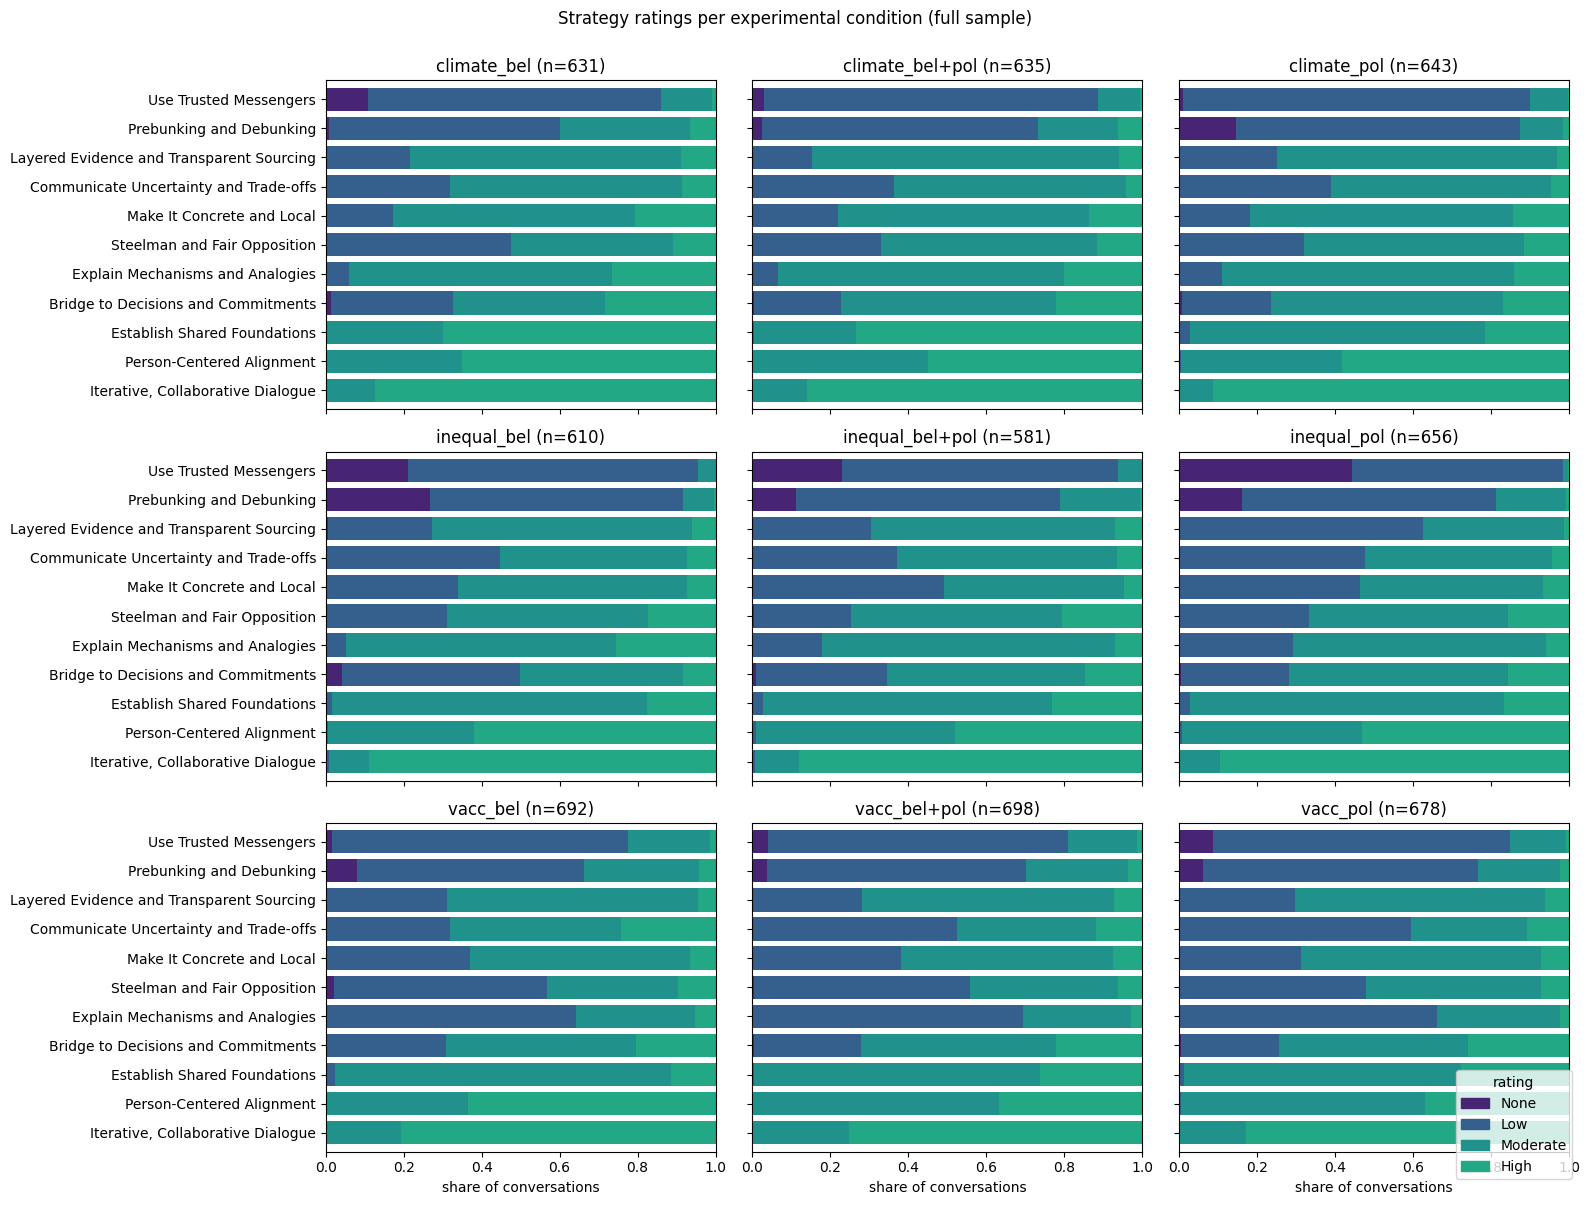

In [15]:
# full experimental sample (control still excluded — it has no condition-specific effect dimension)
df_exp = df_merged[df_merged["condition"] != "control"]

df_long_exp = df_exp.melt(
    id_vars=["X", "condition"],
    value_vars=condition_cols,
    var_name="strategy",
    value_name="rating",
)

# fixed strategy order, based on overall "High" share in the full experimental sample
overall_counts_full = (
    df_long_exp.groupby(["strategy", "rating"]).size()
     .unstack(fill_value=0)
     .reindex(columns=rating_order, fill_value=0)
)
strategy_order_full = overall_counts_full["High"].sort_values(ascending=True).index.tolist()

conditions_full = sorted(df_exp["condition"].unique())

ncols = 3
nrows = (len(conditions_full) + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4 * nrows), sharex=True, sharey=True)
axes = axes.flatten()

for i, cond in enumerate(conditions_full):
    cond_df = df_exp[df_exp["condition"] == cond]
    cond_long = cond_df.melt(
        id_vars="X",
        value_vars=condition_cols,
        var_name="strategy",
        value_name="rating",
    )
    cond_counts = (
        cond_long.groupby(["strategy", "rating"]).size()
         .unstack(fill_value=0)
         .reindex(index=strategy_order_full, columns=rating_order, fill_value=0)
    )
    cond_shares = cond_counts.div(cond_counts.sum(axis=1), axis=0)

    ax = axes[i]
    cond_shares.plot(kind="barh", stacked=True, ax=ax,
                     color=[colors[r] for r in rating_order], width=0.8, legend=False)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_title(f"{cond} (n={cond_df['X'].nunique()})")
    ax.set_xlabel("share of conversations")
    ax.set_ylabel("")

for j in range(len(conditions_full), len(axes)):
    axes[j].set_visible(False)

handles = [plt.Rectangle((0, 0), 1, 1, color=colors[r]) for r in rating_order]
fig.legend(handles, rating_order, title="rating",
           loc="lower right", bbox_to_anchor=(0.99, 0.02))

fig.suptitle("Strategy ratings per experimental condition (full sample)", y=1.0)
plt.tight_layout()
plt.show()

### Heatmap view (full sample)

Same intensity-based view as above (mean intensity and deviation from each strategy's overall mean), but on the full experimental sample rather than the big-effects subset.

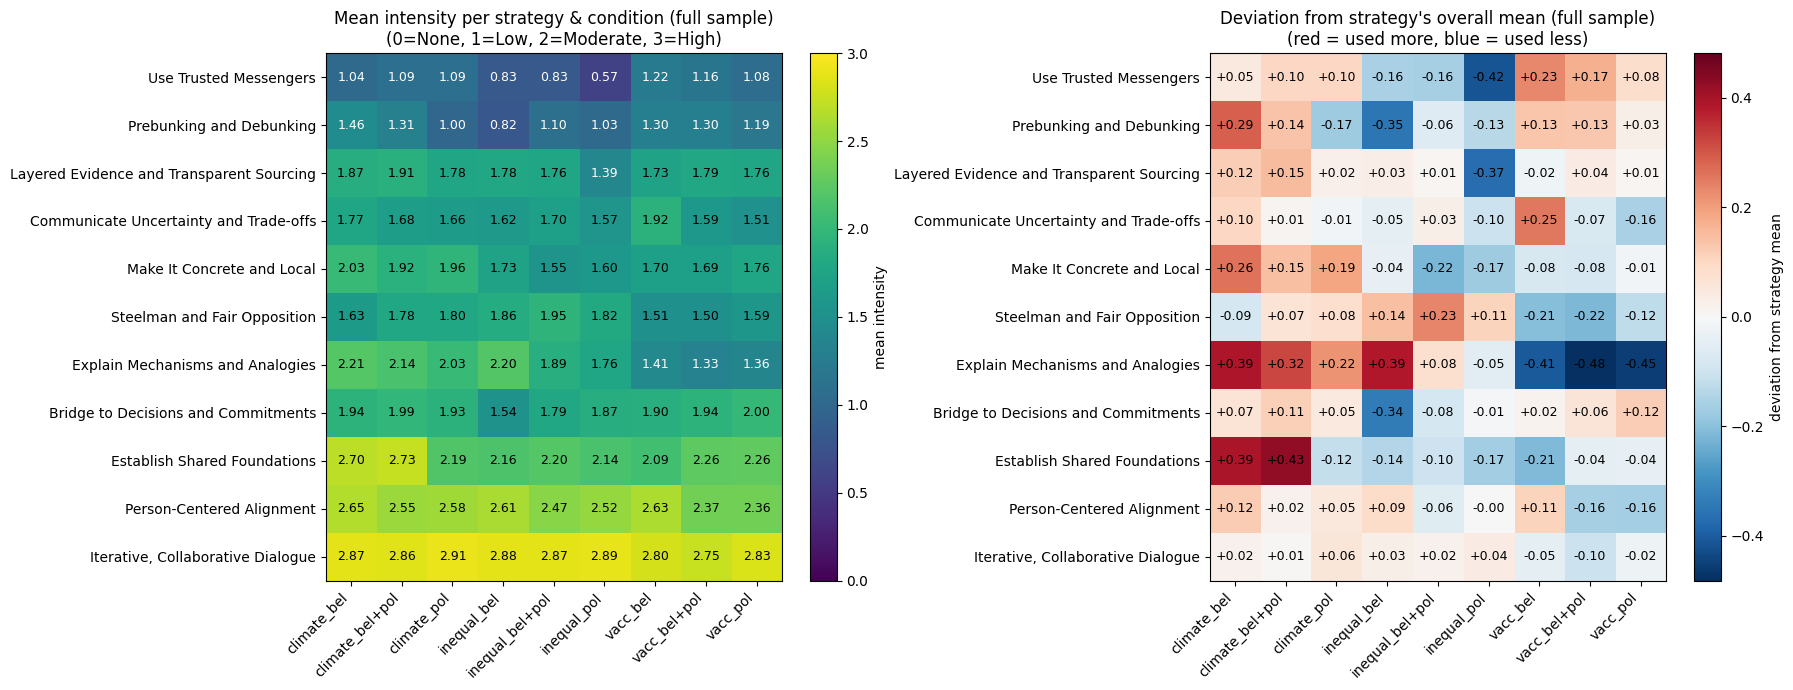

In [16]:
df_long_with_cond_full = df_exp.melt(
    id_vars=["X", "condition"],
    value_vars=condition_cols,
    var_name="strategy",
    value_name="rating",
)
df_long_with_cond_full["intensity"] = df_long_with_cond_full["rating"].map(intensity_map)

mean_intensity_full = (
    df_long_with_cond_full
    .groupby(["strategy", "condition"])["intensity"]
    .mean()
    .unstack("condition")
    .reindex(index=strategy_order_full, columns=conditions_full)
)

strategy_mean_full = mean_intensity_full.mean(axis=1)
deviation_full = mean_intensity_full.sub(strategy_mean_full, axis=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7))

# --- absolute mean intensity ---
im1 = ax1.imshow(mean_intensity_full.values, aspect="auto", cmap="viridis", vmin=0, vmax=3)
ax1.set_xticks(range(len(mean_intensity_full.columns)))
ax1.set_xticklabels(mean_intensity_full.columns, rotation=45, ha="right")
ax1.set_yticks(range(len(mean_intensity_full.index)))
ax1.set_yticklabels(mean_intensity_full.index)
ax1.set_title("Mean intensity per strategy & condition (full sample)\n(0=None, 1=Low, 2=Moderate, 3=High)")
for i in range(mean_intensity_full.shape[0]):
    for j in range(mean_intensity_full.shape[1]):
        val = mean_intensity_full.values[i, j]
        ax1.text(j, i, f"{val:.2f}", ha="center", va="center",
                 color="white" if val < 1.5 else "black", fontsize=9)
plt.colorbar(im1, ax=ax1, label="mean intensity")

# --- deviation from each strategy's overall mean ---
vmax = float(abs(deviation_full.values).max())
im2 = ax2.imshow(deviation_full.values, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax)
ax2.set_xticks(range(len(deviation_full.columns)))
ax2.set_xticklabels(deviation_full.columns, rotation=45, ha="right")
ax2.set_yticks(range(len(deviation_full.index)))
ax2.set_yticklabels(deviation_full.index)
ax2.set_title("Deviation from strategy's overall mean (full sample)\n(red = used more, blue = used less)")
for i in range(deviation_full.shape[0]):
    for j in range(deviation_full.shape[1]):
        val = deviation_full.values[i, j]
        ax2.text(j, i, f"{val:+.2f}", ha="center", va="center", color="black", fontsize=9)
plt.colorbar(im2, ax=ax2, label="deviation from strategy mean")

plt.tight_layout()
plt.show()

## Strategy rating statistics (across all conditions)

Per-strategy descriptive statistics over the full sample (all conditions, including control). Ratings are mapped to an intensity score (None=0, Low=1, Moderate=2, High=3).

In [17]:
ratings_intensity = ratings.copy()
ratings_intensity["intensity"] = ratings_intensity["rating"].map(intensity_map)

strategy_stats = (
    ratings_intensity.groupby("strategy")["intensity"]
    .agg(N="size", mean="mean", sd="std")
    .sort_values("mean", ascending=False)
    .round(3)
)
strategy_stats

,N,mean,sd
strategy,,,
"Iterative, Collaborative Dialogue",6558,2.853,0.361
Person-Centered Alignment,6558,2.574,0.501
Establish Shared Foundations,6558,2.201,0.568
Bridge to Decisions and Commitments,6558,1.882,0.695
Make It Concrete and Local,6558,1.829,0.619
Explain Mechanisms and Analogies,6558,1.718,0.647
Communicate Uncertainty and Trade-offs,6558,1.660,0.630
Steelman and Fair Opposition,6414,1.653,0.682
Layered Evidence and Transparent Sourcing,6558,1.569,0.738


Kleine Extra Erklärung: "Steelman and Fair Opposition" war die einzige Option, bei der es einige Fälle gab, wo GPT-5 die Strategie beim raten nicht richtig benannt hat, wodurch die Ratings nicht gesammelt wurden. Dadurch haben wir da über 1000 missings. 

In [18]:
# summary statistics for all conditions, except the control condition:
# exclude control conversations
non_control_ids = df_merged.loc[df_merged["condition"] != "control", "X"]
ratings_no_control = ratings[ratings["conv_id"].isin(non_control_ids)]


ratings_intensity = ratings_no_control.copy()
ratings_intensity["intensity"] = ratings_intensity["rating"].map(intensity_map)

strategy_stats = (
    ratings_intensity.groupby("strategy")["intensity"]
    .agg(N="size", mean="mean", sd="std")
    .sort_values("mean", ascending=False)
    .round(3)
)
strategy_stats


,N,mean,sd
strategy,,,
"Iterative, Collaborative Dialogue",5824,2.851,0.365
Person-Centered Alignment,5824,2.526,0.507
Establish Shared Foundations,5824,2.301,0.494
Bridge to Decisions and Commitments,5824,1.882,0.717
Explain Mechanisms and Analogies,5824,1.800,0.632
Make It Concrete and Local,5824,1.773,0.610
Layered Evidence and Transparent Sourcing,5824,1.752,0.548
Steelman and Fair Opposition,5691,1.708,0.675
Communicate Uncertainty and Trade-offs,5824,1.669,0.640
